1) Loading the Taxis Dataset

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Taxis dataset
df = sns.load_dataset("taxis")
print(df.shape)
print(df.columns)
df.head()

(6433, 14)
Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


##2) Handling Missing Values
➢ Check for missing values in the dataset and identify columns with missing data.

In [11]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


Used the isnull() function to check every cell in the DataFrame and identify missing values. It returns True if a value is missing and False if a value is present. Then, I used the sum() function to count the True values in each column. Since Python treats True as 1 and False as 0 during calculations, df.isnull().sum() gives the total number of missing values in each column.

In [12]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

,0
payment,44
pickup_zone,26
dropoff_zone,45
pickup_borough,26
dropoff_borough,45


I stored the missing-value counts of each column in a variable called missing_values, which is a Pandas Series. I used the condition missing_values > 0 to check which columns contain missing values. This creates a Boolean condition (True or False) and filters the Series to display only the columns that have at least one missing value.

➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

In [13]:

numerical_columns = df.select_dtypes(include="number").columns

categorical_columns = df.select_dtypes(include=["object", "category"]).columns

print("Numerical columns:", numerical_columns.tolist())
print("Categorical columns:", categorical_columns.tolist())

Numerical columns: ['passengers', 'distance', 'fare', 'tip', 'tolls', 'total']
Categorical columns: ['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


I used the select_dtypes() function to separate columns based on their data types. The include="number" parameter selects numerical columns such as fare, distance, and tip, while include=["object", "category"] selects columns containing text or categorical values. I used .columns to retrieve the column names and .tolist() to convert them into a Python list. Finally, I stored these column names in two variables, numerical_columns and categorical_columns, for further data cleaning.

In [25]:
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

Used a for loop to iterate through each numerical column stored in numerical_columns. For each column, I used the median() function to calculate its middle value and the fillna() function to replace missing values with that median. Finally, I assigned the updated values back to the respective columns in the DataFrame using df[column] = .... For example, if the median fare is 12.50, all missing values in the fare column will be replaced with 12.50.

In [26]:
for column in categorical_columns:
    if df[column].isnull().any():
        mode_value = df[column].mode()

        if not mode_value.empty:
            df[column] = df[column].fillna(mode_value.iloc[0])

Used isnull().any() to check whether each categorical column contains any missing values. Then, I used the mode() function to find the most frequently occurring value in the column. The .empty property checks whether the mode result is empty, while .iloc[0] selects the first mode if multiple values occur with the same frequency. Finally, I used fillna() to replace the missing values with the selected mode, ensuring that the categorical columns contain valid values.

➢ For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

In [16]:
df = df.dropna(subset=["pickup", "fare"])
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


Used the dropna() function with the subset parameter to remove rows containing missing values in the pickup or fare columns. The subset parameter specifies which columns should be checked for missing values. Finally, I assigned the cleaned data back to the df variable so that the DataFrame contains only rows with valid pickup timestamps and fare values.


##3) Visualizations using Matplotlib/Pandas Plot:
★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.



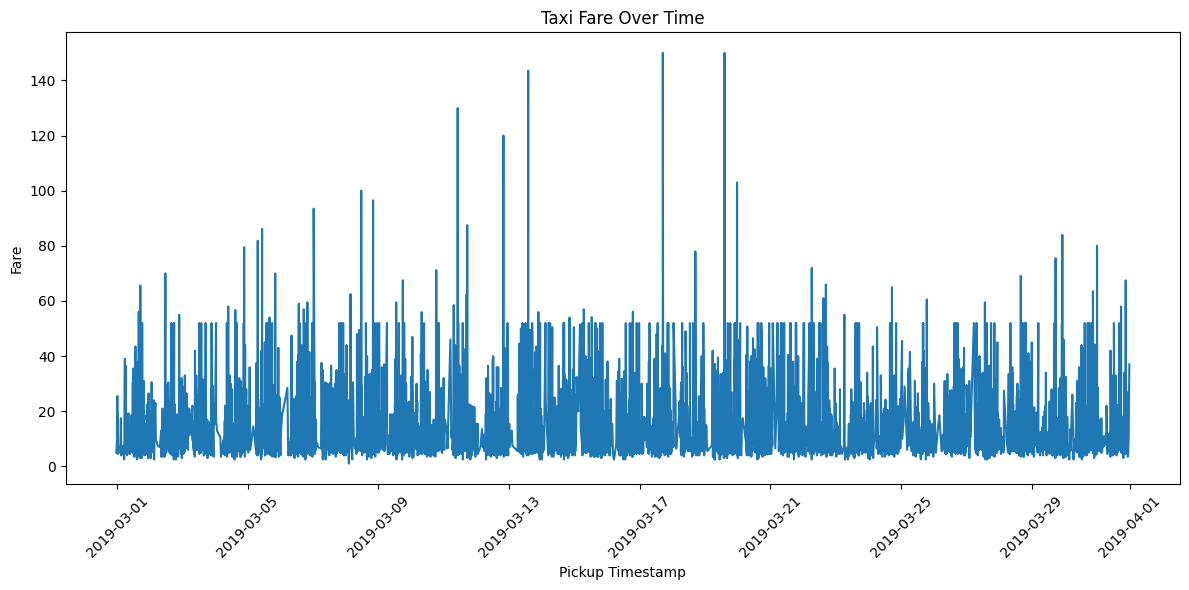

In [17]:

df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")

line_data = df.dropna(subset=["pickup", "fare"]).sort_values("pickup")

plt.figure(figsize=(12, 6))
plt.plot(line_data["pickup"], line_data["fare"])

plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Taxi Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I created a line chart to understand how taxi fares change over time. First, I used the pd.to_datetime() function to convert the pickup column into a datetime data type because it contains date and time information. I used the dropna() function to remove records with missing pickup timestamps or fare values and sort_values() to arrange the records in chronological order. I stored the prepared data in a variable called line_data, which is a Pandas DataFrame. Then, I used Matplotlib's figure() function to set the chart size and plot() function to create the line chart. The pickup timestamp is placed on the x-axis, and fare is placed on the y-axis. I also used xlabel(), ylabel(), and title() to add labels and a title. Finally, xticks() rotates the timestamp labels, tight_layout() adjusts the chart spacing, and show() displays the visualization.

★ Bar Chart
Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

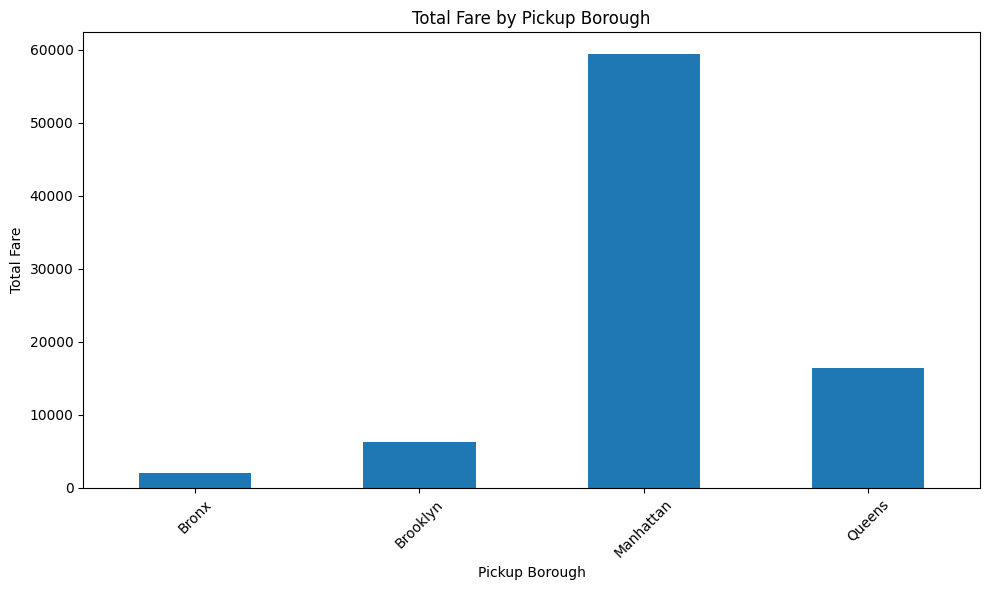

In [18]:

borough_fare = df.groupby("pickup_borough")["fare"].sum()

borough_fare.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I created a bar chart to compare the total taxi fares collected from different pickup boroughs. I used the groupby() function to group the dataset according to the pickup_borough column and selected the fare column to calculate the total fare for each borough. Then, I used the sum() function to add the fare values within each group. The calculated results are stored in a variable called borough_fare, which is a Pandas Series containing borough names and their corresponding total fares. I used the plot() function with kind="bar" to create the bar chart. I also used xlabel(), ylabel(), and title() to describe the axes and chart. This visualization helps compare the total fare amounts across different pickup boroughs.

★ Pie Chart
Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

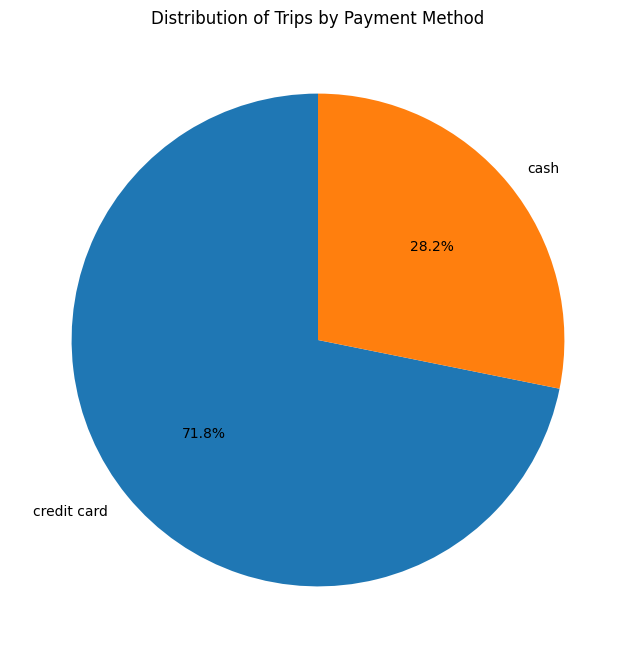

In [19]:

payment_counts = df["payment"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

I used value_counts() to count the number of trips made using each payment method and stored the results in payment_counts. Then, I used Matplotlib's pie() function to create a pie chart showing the distribution of payment methods. I used labels to display payment names and autopct to show percentages on each slice.

★ Histogram
Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

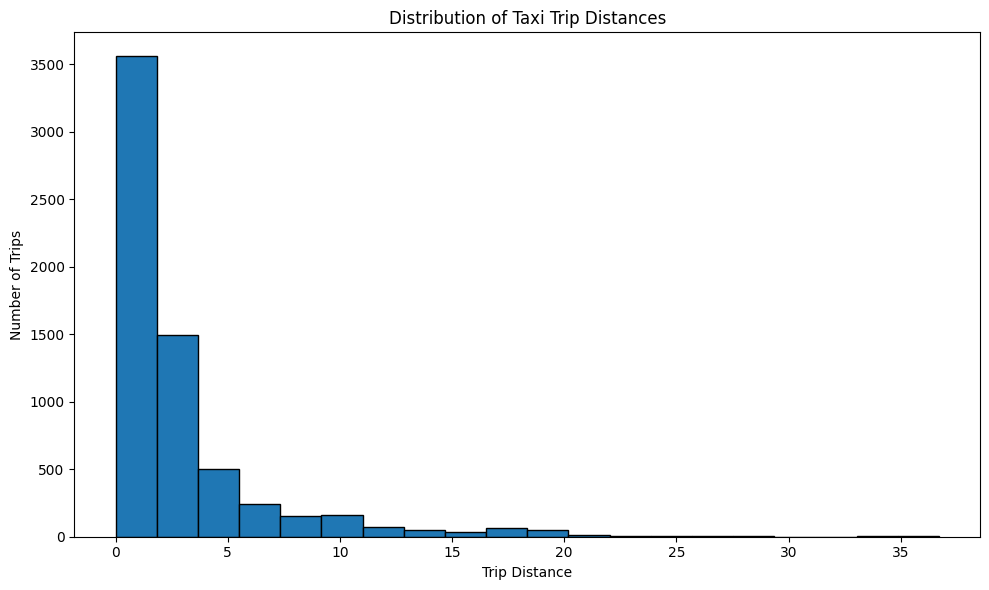

In [20]:

plt.figure(figsize=(10, 6))

plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")

plt.xlabel("Trip Distance")
plt.ylabel("Number of Trips")
plt.title("Distribution of Taxi Trip Distances")
plt.tight_layout()
plt.show()

I selected the distance column from the DataFrame and used dropna() to remove missing values. Then, I used Matplotlib's hist() function to create a histogram with 20 bins. The histogram helps me understand how taxi trip distances are distributed and how many trips fall within different distance ranges.

★ Box Plot
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

<Figure size 1000x600 with 0 Axes>

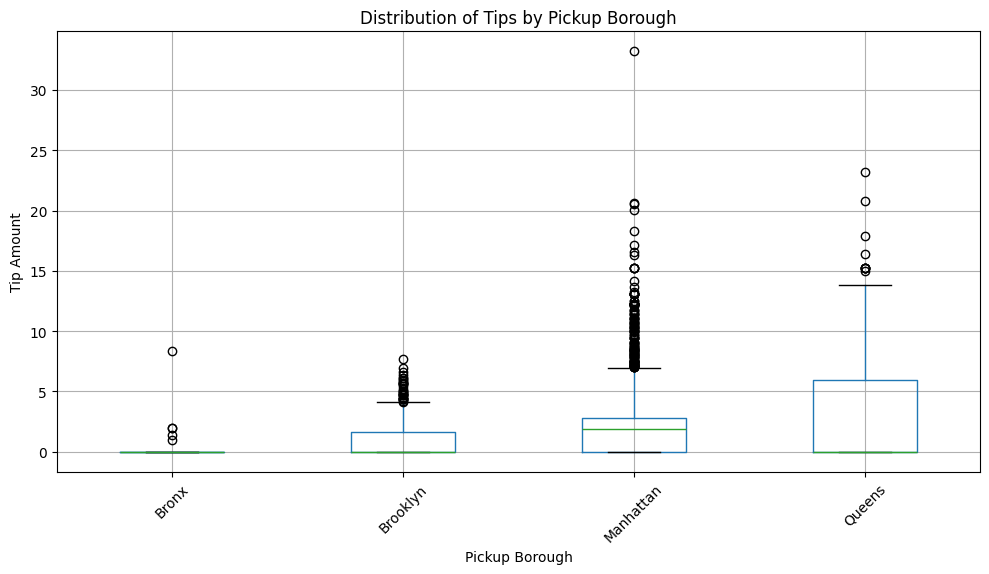

In [21]:

box_data = df.dropna(subset=["pickup_borough", "tip"])

plt.figure(figsize=(10, 6))

box_data.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(10, 6)
)

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I used dropna() to remove rows with missing pickup borough or tip values. Then, I used Pandas' boxplot() function with column="tip" and by="pickup_borough" to compare tip distributions across boroughs. The box plot helps identify the median, spread of tip amounts, and possible outliers in each borough.

##Visualizations using Seaborn:
★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

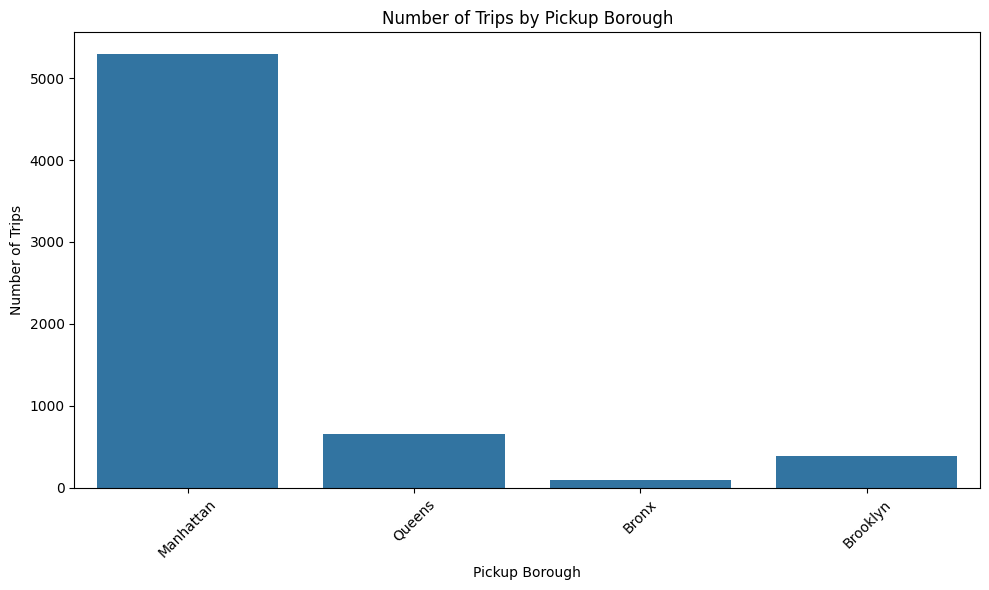

In [22]:

plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="pickup_borough")

plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I used Seaborn's countplot() function to count the number of taxi trips in each pickup borough. I passed the DataFrame using the data parameter and selected pickup_borough for the x-axis. The count plot automatically counts the occurrences of each category and displays them as bars.

★ Scatter Plot
Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

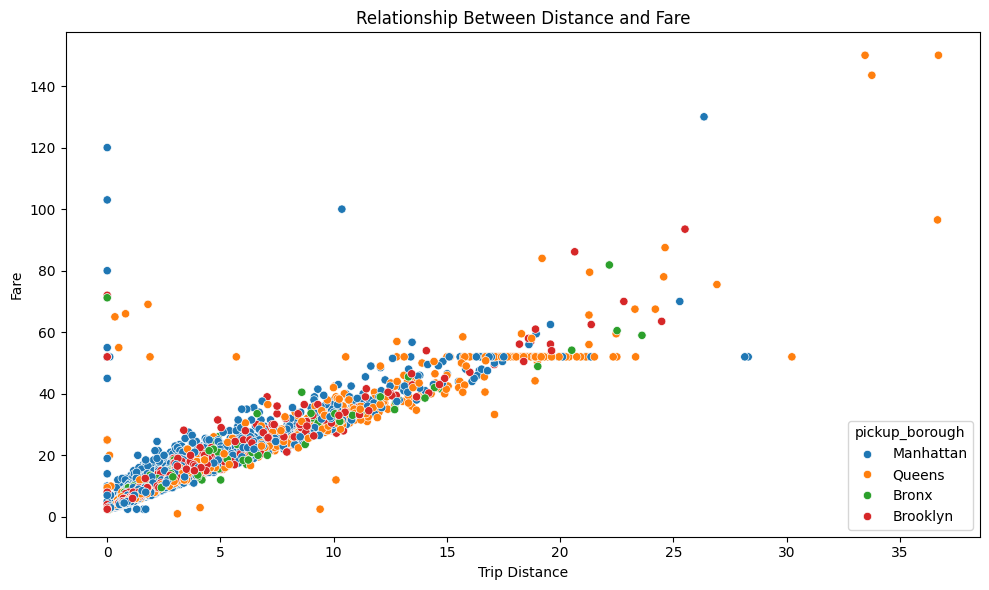

In [23]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.xlabel("Trip Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")
plt.tight_layout()
plt.show()

used Seaborn's scatterplot() function to understand the relationship between taxi distance and fare. I assigned distance to the x-axis and fare to the y-axis. I also used hue="pickup_borough" to represent different boroughs using different colors. Each point represents an individual taxi trip, helping identify whether fares increase with distance.

★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

In [ ]:

numerical_data = df[["distance", "fare", "tip", "tolls", "total"]]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Taxi Variables")
plt.tight_layout()
plt.show()

selected the numerical columns distance, fare, tip, tolls, and total from the DataFrame. I used the corr() function to calculate the correlation between these variables and stored the result in correlation_matrix. Then, I used Seaborn's heatmap() function to visualize the correlation values using different colors. I used annot=True to display the values inside the chart and fmt=".2f" to show them up to two decimal places.

★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

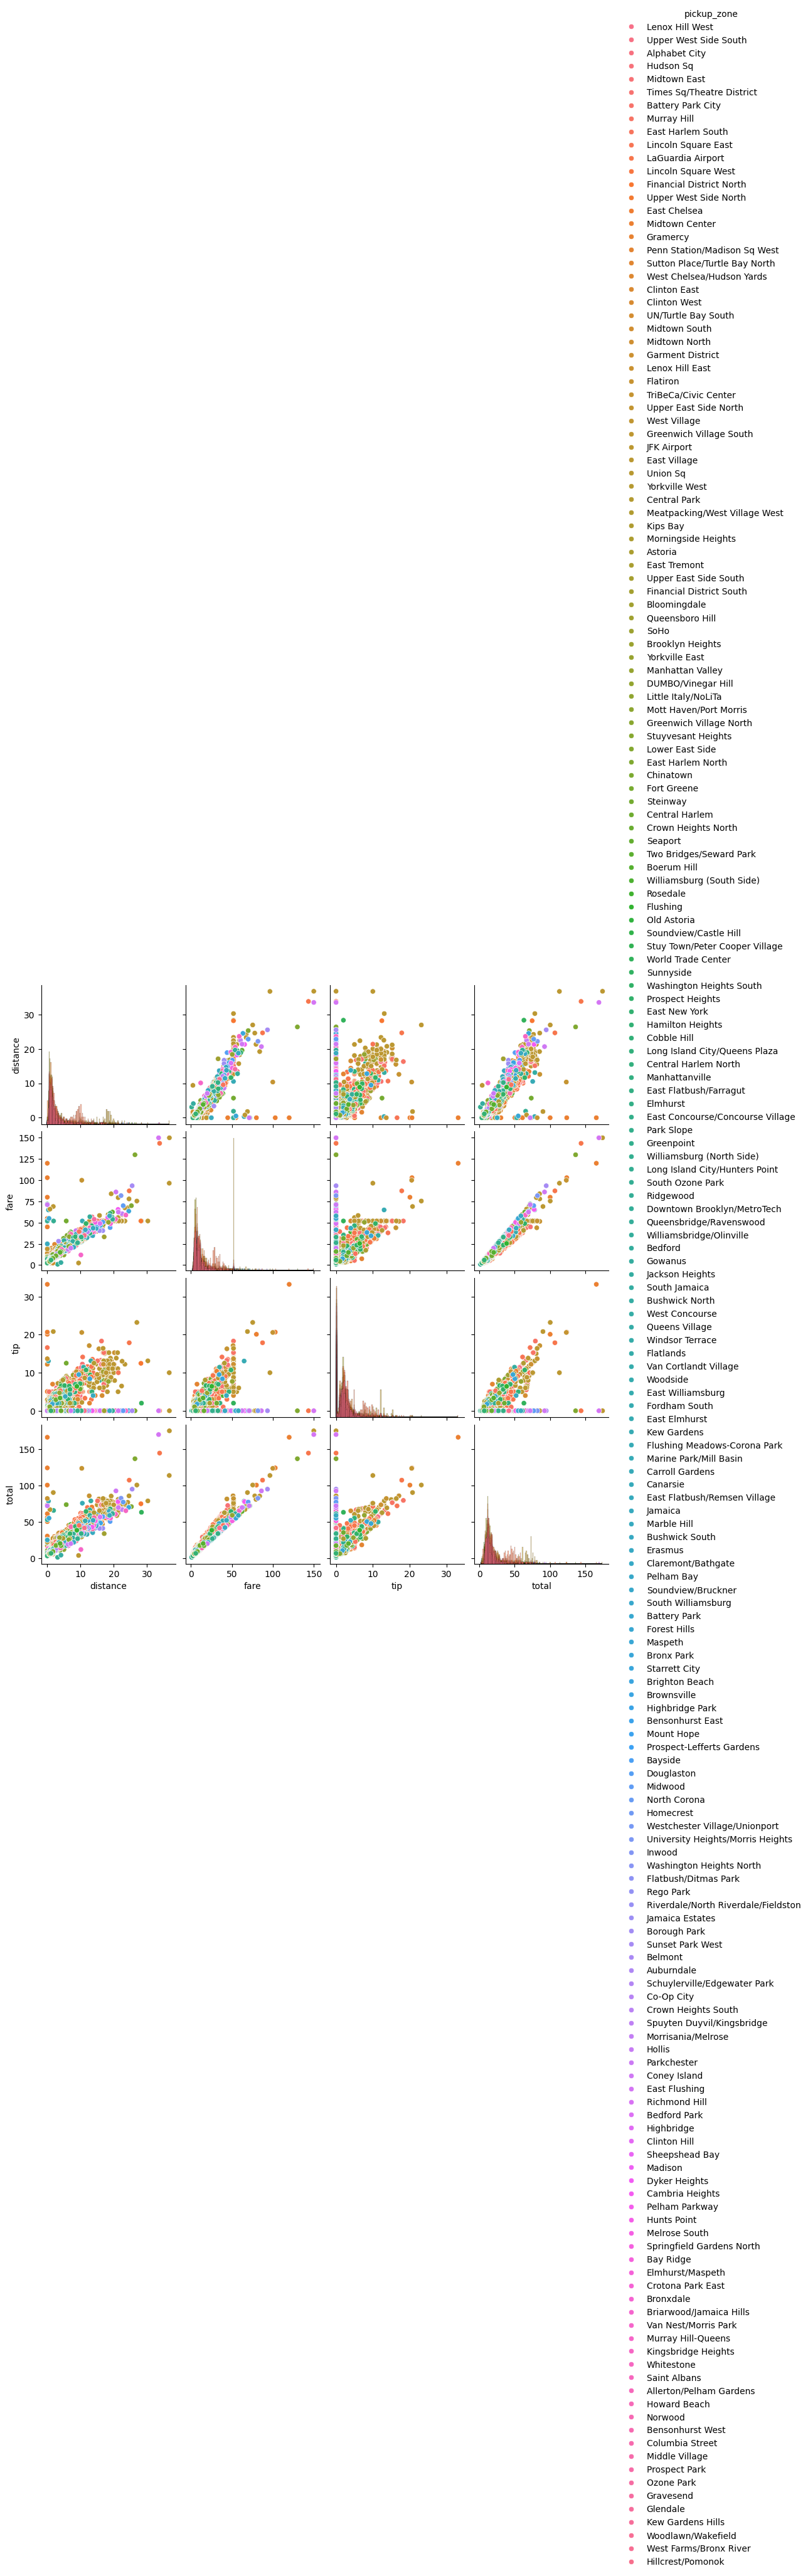

In [27]:

pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()


sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()

I selected the columns distance, fare, tip, total, and pickup_zone from the DataFrame and stored them in pair_data. I used dropna() to remove rows containing missing values. Then, I used Seaborn's pairplot() function to visualize the relationships between the four numerical variables. I used hue="pickup_zone" to distinguish different pickup zones using colors and diag_kind="hist" to display histograms along the diagonal.

★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

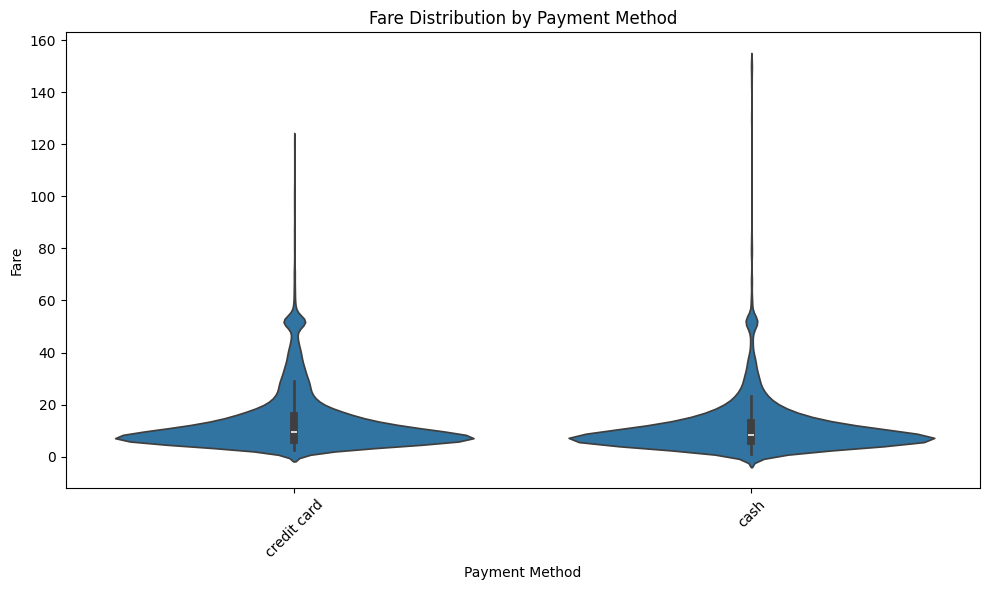

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Used Seaborn's violinplot() function to visualize the distribution of taxi fares across different payment methods. I assigned payment to the x-axis and fare to the y-axis. The violin plot helps understand how fare values are distributed and where observations are more concentrated for each payment category.